# Training and Validation Data Distribution

This notebook determines the observation periods and numbers of trajectories in the final training and validation datasets.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import pyarrow.parquet as pq


PROJECT_ROOT = Path.home() / "Projects" / "OSN_pushback_detection"
FINAL_DATA_ROOT = PROJECT_ROOT / "data" / "train_validation" / "05_final"

SEASON_ORDER = ["Spring", "Summer", "Autumn", "Winter"]
SOUTHERN_HEMISPHERE_AIRPORTS = {"YPPH"}


## Load final datasets

In [2]:
def season_from_month(month: int, southern_hemisphere: bool) -> str:
    if southern_hemisphere:
        if month in (9, 10, 11):
            return "Spring"
        if month in (12, 1, 2):
            return "Summer"
        if month in (3, 4, 5):
            return "Autumn"
        return "Winter"

    if month in (3, 4, 5):
        return "Spring"
    if month in (6, 7, 8):
        return "Summer"
    if month in (9, 10, 11):
        return "Autumn"
    return "Winter"


frames = []

for path in sorted(FINAL_DATA_ROOT.rglob("*.parquet")):
    airport = path.parent.name
    columns = pq.ParquetFile(path).schema.names

    required = ["flight_id", "timestamp"]
    missing = [column for column in required if column not in columns]

    if missing:
        raise ValueError(
            f"{path.name}: missing columns {missing}"
        )

    selected_columns = required.copy()

    if "season" in columns:
        selected_columns.append("season")

    data = pd.read_parquet(
        path,
        columns=selected_columns,
    )

    data["airport"] = airport

    data["timestamp"] = pd.to_datetime(
        data["timestamp"],
        utc=True,
        errors="coerce",
    )

    data = data.dropna(
        subset=["flight_id", "timestamp"]
    )

    if "season" not in data.columns:
        southern = airport in SOUTHERN_HEMISPHERE_AIRPORTS

        data["season"] = data["timestamp"].dt.month.map(
            lambda month: season_from_month(
                month,
                southern_hemisphere=southern,
            )
        )

    frames.append(
        data[
            ["airport", "season", "flight_id", "timestamp"]
        ]
    )


data = pd.concat(
    frames,
    ignore_index=True,
)

data.head()


,airport,season,flight_id,timestamp
0,ESSA,Autumn,AEE761_969,2025-10-08 12:00:02+00:00
1,ESSA,Autumn,AEE761_969,2025-10-08 12:00:03+00:00
2,ESSA,Autumn,AEE761_969,2025-10-08 12:00:04+00:00
3,ESSA,Autumn,AEE761_969,2025-10-08 12:00:05+00:00
4,ESSA,Autumn,AEE761_969,2025-10-08 12:00:06+00:00


## Summary

In [3]:
summary = (
    data
    .groupby(
        ["airport", "season"],
        observed=True,
    )
    .agg(
        start=("timestamp", "min"),
        end=("timestamp", "max"),
        total=("flight_id", "nunique"),
    )
    .reset_index()
)

summary["season"] = pd.Categorical(
    summary["season"],
    categories=SEASON_ORDER,
    ordered=True,
)

summary = (
    summary
    .sort_values(["airport", "season"])
    .reset_index(drop=True)
)

summary


,airport,season,start,end,total
0,ESSA,Spring,2025-04-07 02:38:37+00:00,2025-04-13 20:38:29+00:00,1577
1,ESSA,Summer,2025-07-07 00:17:17+00:00,2025-07-13 21:55:38+00:00,1562
2,ESSA,Autumn,2025-10-06 03:07:14+00:00,2025-10-12 21:46:16+00:00,1758
3,ESSA,Winter,2026-01-13 05:00:16+00:00,2026-01-19 23:58:25+00:00,1283
4,LSZH,Spring,2026-04-20 04:02:03+00:00,2026-04-26 21:05:48+00:00,2464
5,LSZH,Summer,2025-07-21 03:19:33+00:00,2025-07-27 21:20:34+00:00,2334
6,LSZH,Autumn,2025-10-20 03:51:50+00:00,2025-10-26 22:17:12+00:00,2214
7,LSZH,Winter,2026-01-26 05:17:39+00:00,2026-02-01 22:55:57+00:00,1798
8,RJTT,Spring,2025-05-19 00:00:06+00:00,2025-05-25 23:56:24+00:00,2693
9,RJTT,Summer,2025-08-18 00:00:01+00:00,2025-08-24 23:55:14+00:00,2858


## Plot

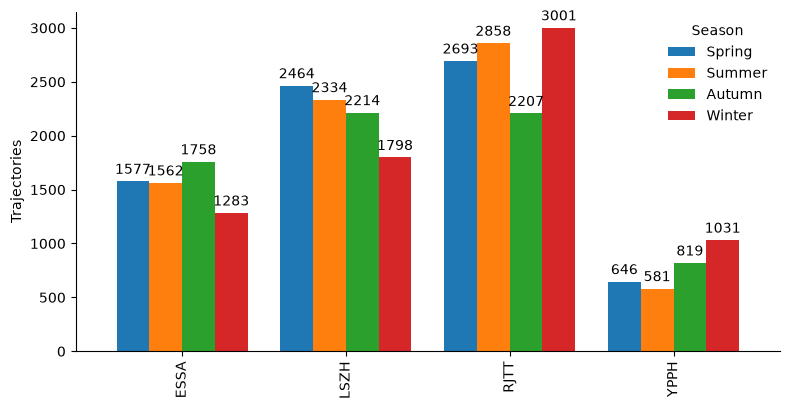

In [4]:
plot_data = (
    summary
    .pivot(
        index="airport",
        columns="season",
        values="total",
    )
    .reindex(columns=SEASON_ORDER)
)

ax = plot_data.plot(
    kind="bar",
    figsize=(8.0, 4.2),
    width=0.8,
)

ax.set_xlabel("")
ax.set_ylabel("Trajectories")
ax.legend(title="Season", frameon=False)

for container in ax.containers:
    labels = [
        f"{bar.get_height():.0f}"
        if np.isfinite(bar.get_height())
        else ""
        for bar in container
    ]
    ax.bar_label(
        container,
        labels=labels,
        padding=3,
    )

ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

plt.tight_layout()
plt.show()
